This file uses the ranked features from the `featureRankingBCG_Impurity.ipynb` file and does a simple single-pass pairwise correlation analysis. The final, more sophisticated version of this file is the `featureCorrelationIterative.ipynb`.

In [12]:
import pickle
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

In [13]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

In [14]:
def remove_highly_correlated_features(top_features, data, pcc=0.8):
    feature_names = [f for f,_ in top_features]
    importances   = {f: imp for f, imp in top_features}
    X = data[feature_names]

    # Find the correlated pairs
    correlated_pairs = []
    for i in range(len(feature_names)):
        for j in range(i+1, len(feature_names)):
            f1, f2 = feature_names[i], feature_names[j]
            r, p = pearsonr(X[f1], X[f2])
            # check if this is 'and' or 'or'?
            if abs(r) >= pcc and p < 0.05:
                correlated_pairs.append((f1, f2, r, p))

    # remove the correlated feature of lower importance
    toDrop = set()
    for f1, f2, r, p in correlated_pairs:
        if f1 not in toDrop and f2 not in toDrop:
            drop = f2 if importances[f1] >= importances[f2] else f1
            toDrop.add(drop)

    filtered = [(f,imp) for f,imp in top_features if f not in toDrop]   # kept features
    
    return filtered, correlated_pairs, toDrop

{'folds': 5, 'seeds': [42, 12, 0, 4, 77], 'n_estimator': 100, 'feature_importance_SBP': array([1.04342639e-01, 1.03243993e-01, 4.77116644e-02, 3.93100839e-02,
       3.46319012e-02, 3.10316562e-02, 2.73061962e-02, 2.71361025e-02,
       2.65691829e-02, 2.21124920e-02, 2.00341745e-02, 1.88322866e-02,
       1.70236901e-02, 1.58464890e-02, 1.50850187e-02, 1.32005533e-02,
       1.22350630e-02, 1.14176312e-02, 1.00576304e-02, 9.74410508e-03,
       8.35948102e-03, 7.79467977e-03, 6.74876750e-03, 6.59685423e-03,
       6.58823944e-03, 6.53667635e-03, 6.29748880e-03, 6.25073971e-03,
       5.90355214e-03, 5.78278136e-03, 5.75023827e-03, 5.67693781e-03,
       5.21880141e-03, 4.86949516e-03, 4.68255525e-03, 4.34885147e-03,
       4.22585002e-03, 4.13336429e-03, 4.12493839e-03, 4.02343219e-03,
       3.96658023e-03, 3.96437261e-03, 3.94818693e-03, 3.93096836e-03,
       3.74916386e-03, 3.72076965e-03, 3.72075281e-03, 3.64924245e-03,
       3.64887844e-03, 3.51731728e-03, 3.48704794e-03, 3.450

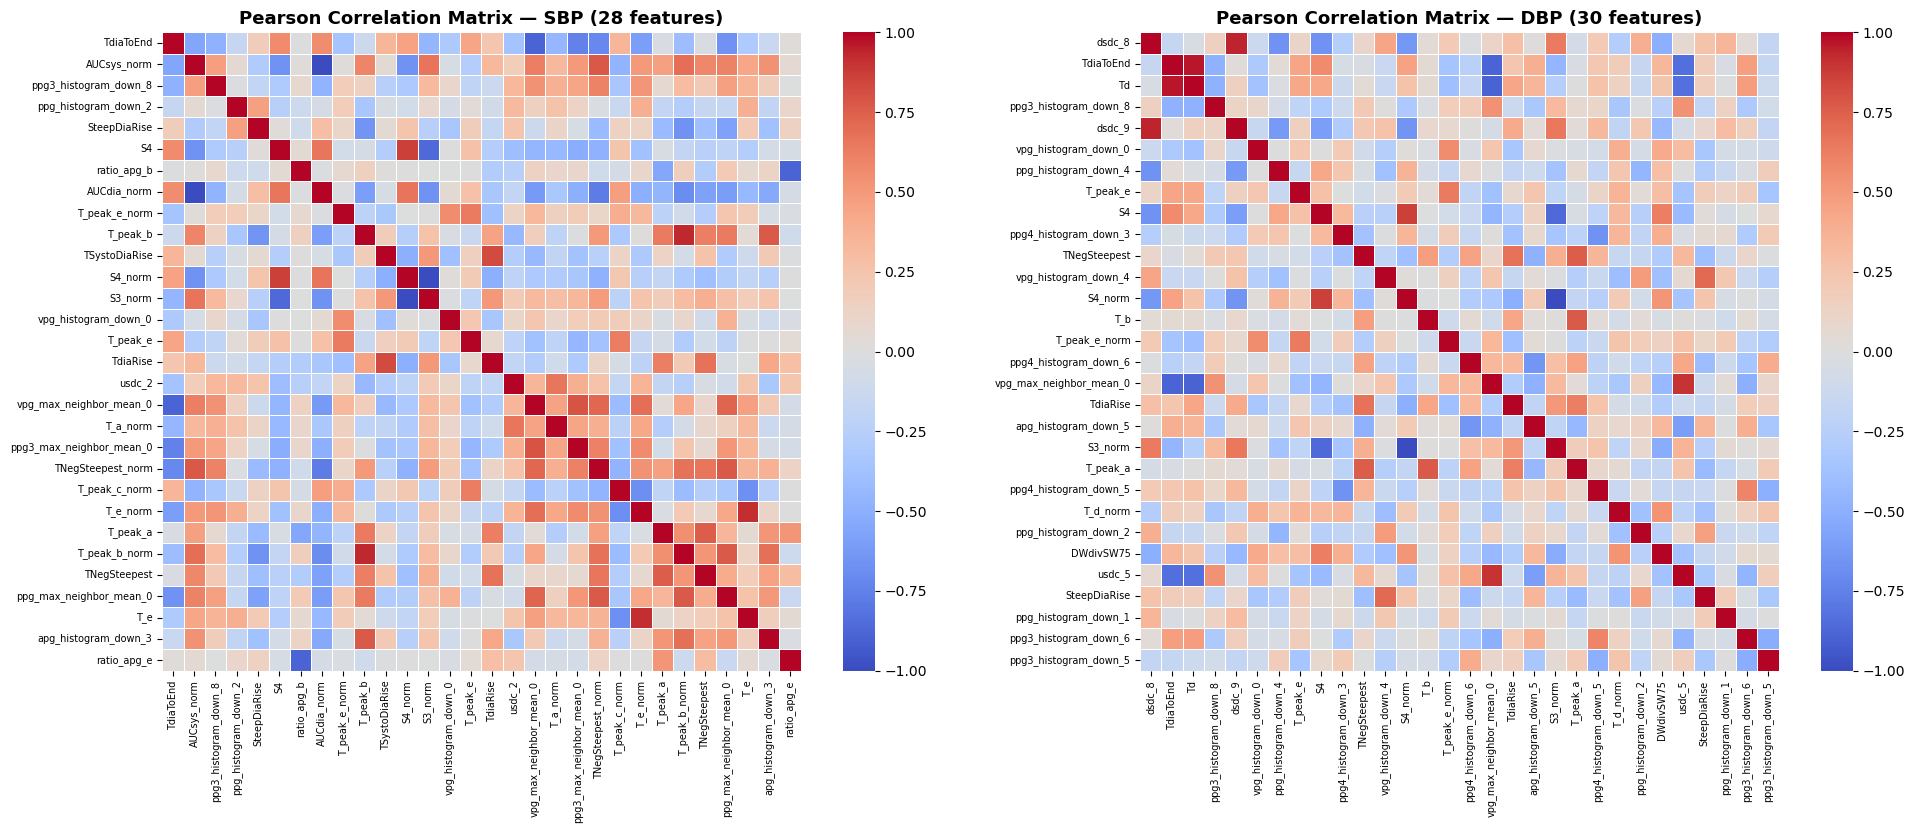

For SBP: 
Filtered Features [('TdiaToEnd', np.float64(0.10434263860901927)), ('AUCsys_norm', np.float64(0.10324399339094206)), ('ppg3_histogram_down_8', np.float64(0.04771166442589053)), ('ppg_histogram_down_2', np.float64(0.03931008386323786)), ('SteepDiaRise', np.float64(0.03463190119158593)), ('S4', np.float64(0.03103165623471341)), ('ratio_apg_b', np.float64(0.027306196221719134)), ('T_peak_e_norm', np.float64(0.026569182857751734)), ('T_peak_b', np.float64(0.022112492027577355)), ('TSystoDiaRise', np.float64(0.020034174522951153)), ('vpg_histogram_down_0', np.float64(0.01584648900415021)), ('T_peak_e', np.float64(0.01508501870100755)), ('usdc_2', np.float64(0.0122350630077648)), ('T_a_norm', np.float64(0.010057630412170726)), ('ppg3_max_neighbor_mean_0', np.float64(0.00974410507676312)), ('TNegSteepest_norm', np.float64(0.008359481016014853)), ('T_peak_c_norm', np.float64(0.007794679769408309)), ('T_e_norm', np.float64(0.006748767498478074)), ('T_peak_a', np.float64(0.006596854228

In [16]:
with open("FeatureRanking_Results/rf_results.pkl", "rb") as file:
    results = pickle.load(file)

print(results)

SBP_features = [(f,imp) for (f, imp) in results["sbp_ranking"][:218]]
DBP_features = [(f,imp) for (f, imp) in results["dbp_ranking"][:218]]
print(SBP_features[0][0])

# Get the top features to get over 2/3 of total feature importance
sumImpSBP = 0
sumImpDBP = 0
num_features_SBP = 0
num_features_DBP = 0
PCC = 0.8                # Pearson Correlation Coefficient

for i in range (len(SBP_features)):
    sumImpSBP += SBP_features[i][1]
    num_features_SBP += 1
    if sumImpSBP>=0.66:
        break

for i in range (len(DBP_features)):
    sumImpDBP += DBP_features[i][1]
    num_features_DBP += 1
    if sumImpDBP>=0.66:
        break

print(f"Top SBP {num_features_SBP} features with a cumulative importance of {sumImpSBP}")
for i, (f, imp) in enumerate(SBP_features[:num_features_SBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

print(f"\n\nTop SBP {num_features_DBP} features with a cumulative importance of {sumImpDBP}")
for i, (f, imp) in enumerate(DBP_features[:num_features_DBP], 1):
    print(f"{i:>3} {f:<40} {imp:.6f}")

top_N_features = num_features_SBP if num_features_SBP >= num_features_DBP else num_features_DBP

# Keep tuples with importance
top_features_SBP = results["sbp_ranking"][:top_N_features]
top_features_DBP = results["dbp_ranking"][:top_N_features]

# Only feature names
top_feature_names_SBP = [f for f, _ in top_features_SBP]
top_feature_names_DBP = [f for f, _ in top_features_DBP]

data = load_all_data()

X_SBP = data[top_feature_names_SBP]
X_DBP = data[top_feature_names_DBP]

corr_SBP = X_SBP.corr(method="pearson")
corr_DBP = X_DBP.corr(method="pearson")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sb.heatmap(
    corr_SBP,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,
    xticklabels=True,
    yticklabels=True
)
axes[0].set_title(f'Pearson Correlation Matrix — SBP ({num_features_SBP} features)', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=90, labelsize=7)
axes[0].tick_params(axis='y', rotation=0,  labelsize=7)

sb.heatmap(
    corr_DBP,
    ax=axes[1],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    annot=False,
    xticklabels=True,
    yticklabels=True
)
axes[1].set_title(f'Pearson Correlation Matrix — DBP ({num_features_DBP} features)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=90, labelsize=7)
axes[1].tick_params(axis='y', rotation=0,  labelsize=7)

plt.tight_layout()
plt.savefig('FeatureRanking_Results/pearson_correlation_matrix_single.png', dpi=300, bbox_inches='tight')
plt.show()

# I define high correlation, if absolute(r) ≥ 0.85 and p < 0.05
filtered_SBP, pairs_SBP, dropped_SBP = remove_highly_correlated_features(top_features_SBP, data, pcc=PCC)
print(f"For SBP: \nFiltered Features {filtered_SBP} \nHighly correlated values {pairs_SBP} \nDropped features {dropped_SBP}\n\n")

filtered_DBP, pairs_DBP, dropped_DBP = remove_highly_correlated_features(top_features_DBP, data, pcc=PCC)
print(f"For DBP: \nFiltered Features {filtered_DBP} \nHighly correlated values {pairs_DBP} \nDropped features {dropped_DBP}")

'''
filtered_names_sbp = [f for f,_ in filtered_SBP]
filtered_names_dbp = [f for f,_ in filtered_DBP]
filtered_importances_sbp = [imp for _,imp in filtered_SBP]
filtered_importances_dbp = [imp for _,imp in filtered_DBP]
'''

with open("FeatureRanking_Results/rf_results.pkl", "rb") as f:
    file = pickle.load(f)

file.update({
    "sbp_ranking_pearson": filtered_SBP,
    "dbp_ranking_pearson": filtered_DBP
})
print([f for f,_ in filtered_SBP])
print([f for f,_ in filtered_DBP])

with open("FeatureRanking_Results/rf_results.pkl", "wb") as f:
    pickle.dump(file, f)
